# Extension: Do Natural Gas Prices Improve the Forecast?

*A follow-up to [Forecasting US Electricity Prices](electricity_price_forecast.ipynb), the AI-assisted revision of my M.S. Data Analytics capstone, produced with Claude (Anthropic). My [original capstone](../../D214-capstone-electricity-price-forecast/) proposed this as further work: adding an outside driver such as natural gas prices to the SARIMA model (SARIMAX).*

**Question:** does adding the Henry Hub natural gas price improve 1–12 month forecasts of the US average electricity price?

## Summary

- **Gas adds little.** Adding the Henry Hub price, lagged seven months (a lag chosen from data before the test period), lowered the average 1–12 month error from 2.48% to 2.44%. It was the more accurate model from 13 of 25 forecast origins. That is too small and too inconsistent to call an improvement.
- **Knowing future gas prices wouldn't change much.** With the actual gas prices supplied, the error was 2.39%.
- **The result depends on how gas enters the model.** Among other designs tried afterwards, a six-month trailing average of the gas price cut the error to 2.11%, while a 12-month trailing average raised it to 2.67%. Because these were explored after the fact, the 2.11% is a lead worth testing on new data, not a finding.
- **Gas doesn't fix the main weakness.** For forecasts made around the 2021–22 surge, the error fell only from 4.5% to 4.4%.
- **A side finding matters more.** A fixed, standard SARIMA (2.48%) was more accurate than the automatically selected SARIMA in the main notebook (3.34%), and better than every other method there over the 1–12 month range.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels convergence chatter; convergence is checked explicitly below

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.precision", 2)

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

## 1. Data

- **Electricity:** the same BLS series as the main notebook, in ¢/kWh, March 2016 to March 2026. October 2025 (never collected, because of the government shutdown) is interpolated as model input and left out of all scoring.
- **Natural gas:** the monthly average Henry Hub spot price in dollars per million Btu, from the U.S. Energy Information Administration (series RNGWHHD). Henry Hub is the main US benchmark for natural gas, and gas is the largest single fuel for US electricity generation.

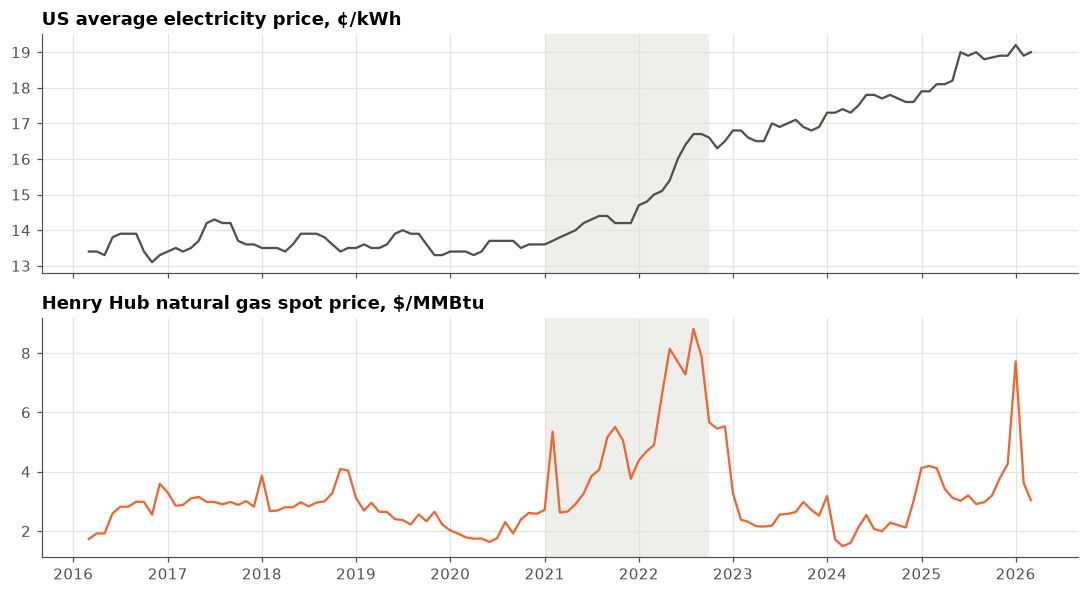

In [2]:
raw = pd.read_csv("data/APU000072610.csv", parse_dates=["observation_date"], index_col="observation_date")
price = (raw["APU000072610"] * 100).rename("cents_per_kwh").asfreq("MS")
FILLED = price[price.isna()].index  # no real observation; excluded from scoring
price = price.interpolate()

gas = pd.read_csv("data/henry_hub_monthly_eia.csv", parse_dates=["observation_date"],
                  index_col="observation_date")["henry_hub_usd_per_mmbtu"].asfreq("MS")
assert gas.isna().sum() == 0

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(price, color=INK_2, lw=1.5)
axes[0].set(title="US average electricity price, ¢/kWh")
axes[1].plot(gas[price.index[0]:price.index[-1]], color=ORANGE, lw=1.5)
axes[1].set(title="Henry Hub natural gas spot price, $/MMBtu")
for ax in axes:
    ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2022-10-01"), color=GRID, alpha=0.6, lw=0)
plt.tight_layout()
plt.show()

Gas prices roughly tripled between early 2021 and mid-2022, over the same period as the electricity price surge (shaded). Gas then fell back to its earlier range, apart from brief winter spikes, while electricity prices stayed high and kept rising. So gas plausibly explains the timing of the surge, but not the level electricity prices have held since.

## 2. Does gas lead electricity, and by how long?

Retail electricity rates don't move with fuel costs straight away. Utilities pass fuel costs through in regulated rate adjustments, which takes months. To choose a lag without looking at the test period, the correlation below uses **only the data before the first forecast origin** (through March 2019). It compares the year-over-year change in the electricity price with the year-over-year change in the gas price 0 to 12 months earlier.

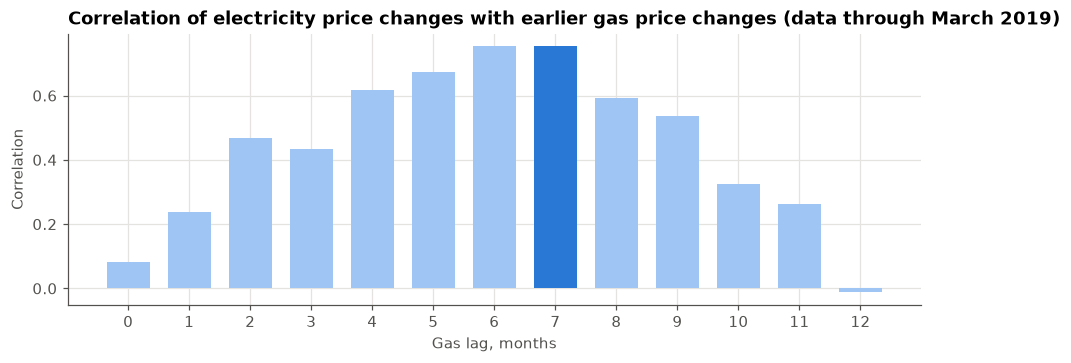

Strongest at a lag of 7 months (r = 0.75), from 25 monthly observations


In [3]:
FIRST_ORIGIN = pd.Timestamp("2019-03-01")
elec_yoy = price.diff(12).dropna()[:FIRST_ORIGIN]
gas_yoy = gas.diff(12)
xcorr = pd.Series({lag: elec_yoy.corr(gas_yoy.shift(lag).reindex(elec_yoy.index)) for lag in range(13)})
GAS_LAG = int(xcorr.idxmax())

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(xcorr.index, xcorr.values, color=[BLUE if lag == GAS_LAG else "#9ec5f4" for lag in xcorr.index], width=0.7)
ax.set(title="Correlation of electricity price changes with earlier gas price changes (data through March 2019)",
       xlabel="Gas lag, months", ylabel="Correlation", xticks=range(13))
plt.show()
print(f"Strongest at a lag of {GAS_LAG} months (r = {xcorr.max():.2f}), from {len(elec_yoy)} monthly observations")

The correlation peaks at a lag of seven months (0.75, with six months almost identical), so the model uses **the gas price seven months earlier**. One caveat: this rests on only 25 months, from a period when both prices were fairly quiet.

A seven-month lag has a practical advantage. A forecast up to seven months ahead needs only gas prices that are already known. Beyond that, the model needs a gas price that hasn't happened yet, and section 3 handles that in two ways.

## 3. Design

The backtest is the same as in the main notebook: 25 forecast origins (quarterly, March 2019 to March 2025), each model refitted on the data available at the origin, forecasts scored 1–12 months ahead.

To isolate the effect of gas, both SARIMA models use the same fixed structure, SARIMA(0,1,1)(0,1,1)₁₂. This is the standard "airline" model, a common default for monthly seasonal data. The only difference between them is the gas term.

| Model | What it does |
|---|---|
| **SARIMA** | SARIMA(0,1,1)(0,1,1)₁₂ on electricity prices alone. |
| **SARIMA + gas** | The same model with the gas price seven months earlier as a regressor. Where a forecast needs a future gas price, it assumes gas stays at its last observed value. This is a forecast that could really have been made. |
| **SARIMA + gas (actual future gas)** | The same, but given the gas prices that actually occurred. This couldn't be done in practice. It shows the most that this gas term could add if gas were forecast perfectly. |
| **Drift, ETS** | From the main notebook, for reference. |

In [4]:
HORIZON = 12
ORIGINS = pd.date_range(FIRST_ORIGIN, "2025-03-01", freq="3MS")
ORDER, SEASONAL = (0, 1, 1), (0, 1, 1, 12)


def gas_paths(origin, future_index):
    # Gas as known at the origin (future held at the last value), and as it actually turned out
    known = gas[:origin]
    held = pd.concat([known, pd.Series(known.iloc[-1], index=future_index)])
    return held, gas[:future_index[-1]]


def sarima(train, h, exog=None, exog_future=None, trend=None):
    fit = SARIMAX(train, exog=exog, order=ORDER, seasonal_order=SEASONAL, trend=trend).fit(disp=False)
    return fit.forecast(h, exog=exog_future).values, fit.mle_retvals["converged"]


def gas_forecast(train, future_index, gas_series, transform):
    x = transform(gas_series)
    return sarima(train, len(future_index), exog=x[train.index], exog_future=x[future_index])


def run_backtest(extra=None):
    records, converged = [], []
    for origin in ORIGINS:
        train = price[:origin]
        actual = price[origin + pd.DateOffset(months=1):].iloc[:HORIZON]
        held, true = gas_paths(origin, actual.index)
        lag = lambda g: g.shift(GAS_LAG)
        slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
        fc = {
            "Drift": (train.iloc[-1] + slope * np.arange(1, HORIZON + 1), True),
            "ETS": (ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add",
                                         seasonal_periods=12).fit().forecast(HORIZON).values, True),
            "SARIMA": sarima(train, HORIZON),
            "SARIMA + gas": gas_forecast(train, actual.index, held, lag),
            "SARIMA + gas (actual future gas)": gas_forecast(train, actual.index, true, lag),
        }
        for name, make in (extra or {}).items():
            fc[name] = make(train, actual.index, held, true)
        for name, (values, ok) in fc.items():
            converged.append(ok)
            for h, (date, y, f) in enumerate(zip(actual.index, actual.values, values), start=1):
                if date in FILLED:
                    continue
                records.append({"origin": origin, "model": name, "h": h, "actual": y, "forecast": f})
    bt = pd.DataFrame(records)
    bt["abs_err"] = (bt["actual"] - bt["forecast"]).abs()
    bt["ape"] = 100 * bt["abs_err"] / bt["actual"]
    print(f"{len(bt):,} scored forecasts; {sum(converged)} of {len(converged)} model fits converged")
    return bt


def by_horizon(bt, models):
    bands = {"1–12 mo": range(1, 13), "1–3 mo": range(1, 4), "4–6 mo": range(4, 7),
             "7–9 mo": range(7, 10), "10–12 mo": range(10, 13)}
    table = pd.DataFrame({f"MAPE %, {k}": bt[bt["h"].isin(v)].groupby("model")["ape"].mean() for k, v in bands.items()})
    return table.loc[models]


bt = run_backtest()

1,490 scored forecasts; 125 of 125 model fits converged


## 4. Results

In [5]:
MAIN = ["SARIMA + gas (actual future gas)", "SARIMA + gas", "SARIMA", "Drift", "ETS"]
by_horizon(bt, MAIN)

,"MAPE %, 1–12 mo","MAPE %, 1–3 mo","MAPE %, 4–6 mo","MAPE %, 7–9 mo","MAPE %, 10–12 mo"
model,,,,,
SARIMA + gas (actual future gas),2.39,1.10,2.13,2.93,3.44
SARIMA + gas,2.44,1.10,2.13,2.99,3.58
SARIMA,2.48,1.07,2.17,3.05,3.64
Drift,2.69,1.52,2.52,3.10,3.64
ETS,2.77,1.10,2.23,3.32,4.47


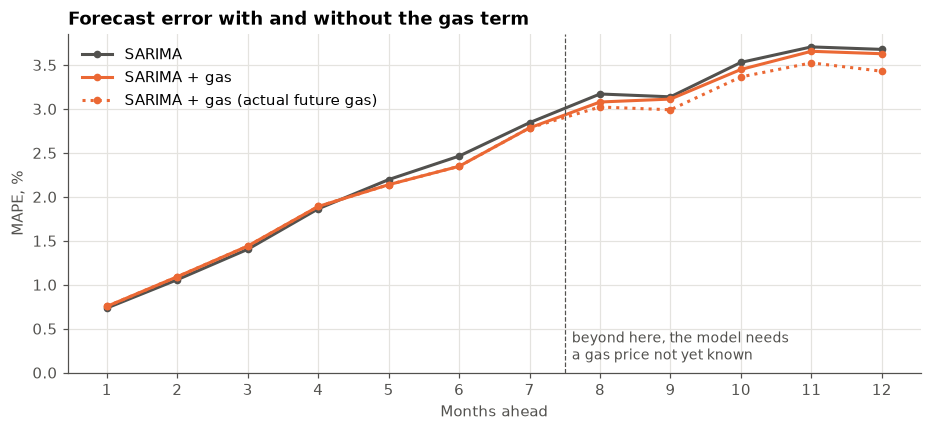

SARIMA + gas was more accurate than SARIMA from 13 of 25 origins


era,2019 – early 2020,mid-2020 – mid-2022 (surge),mid-2022 – 2025
model,,,
SARIMA + gas (actual future gas),0.89,4.24,1.78
SARIMA + gas,0.92,4.35,1.80
SARIMA,0.94,4.47,1.78


In [6]:
curve = bt.groupby(["model", "h"])["ape"].mean().unstack("model")
styles = {"SARIMA": (INK_2, "-"), "SARIMA + gas": (ORANGE, "-"), "SARIMA + gas (actual future gas)": (ORANGE, ":")}

fig, ax = plt.subplots(figsize=(10, 4))
for name, (color, ls) in styles.items():
    ax.plot(curve.index, curve[name], color=color, ls=ls, marker="o", ms=4, label=name)
ax.axvline(GAS_LAG + 0.5, color=INK_2, lw=0.8, ls="--")
ax.text(GAS_LAG + 0.6, 0.15, "beyond here, the model needs\na gas price not yet known", fontsize=9, color=INK_2)
ax.set(title="Forecast error with and without the gas term", xlabel="Months ahead", ylabel="MAPE, %",
       xticks=range(1, 13), ylim=(0, None))
ax.legend(loc="upper left")
plt.show()

err = bt.groupby(["origin", "model"])["abs_err"].mean().unstack()
print(f"SARIMA + gas was more accurate than SARIMA from {(err['SARIMA + gas'] < err['SARIMA']).sum()} of {len(err)} origins")

era = np.where(bt["origin"] < "2020-06-01", "2019 – early 2020",
               np.where(bt["origin"] < "2022-06-01", "mid-2020 – mid-2022 (surge)", "mid-2022 – 2025"))
bt.assign(era=era).pivot_table(index="model", columns="era", values="ape", aggfunc="mean").loc[MAIN[:3]]

- **The gain from gas is small.** Over 1–12 months the gas model averages 2.44%, against 2.48% without gas. It was the more accurate of the two from 13 of the 25 origins, which is about what chance would give.
- **Even perfect knowledge of future gas prices adds little** (2.39%). The two gas lines coincide for the first seven months, where no future gas price is needed, and separate only slightly after that.
- **Gas doesn't solve the surge.** For forecasts made from mid-2020 to mid-2022, the error falls from 4.47% to 4.35%. The gas price did rise sharply before electricity prices did (section 1), but a single lagged term, in a model fitted mostly on quiet years, captures little of that.
- Both SARIMA models are ahead of drift and ETS at most horizons, and level with drift at 10–12 months.

## 5. How much does the result depend on how gas enters the model?

The seven-month lag was chosen by a rule, before the backtest. To see how sensitive the result is to that choice, this section tries other reasonable ways of including gas: shorter and longer lags, and trailing averages of the gas price. **These alternatives were explored after the main result, so the best of them is not a fair estimate of what gas adds.** They're shown to indicate how stable the finding is.

In [7]:
def variant(transform):
    def make(train, future_index, held, true):
        return gas_forecast(train, future_index, held, transform)
    return make


VARIANTS = {
    "Gas, 3-month lag": variant(lambda g: g.shift(3)),
    "Gas, 9-month lag": variant(lambda g: g.shift(9)),
    "Gas, 6-month trailing average": variant(lambda g: g.rolling(6).mean()),
    "Gas, 12-month trailing average": variant(lambda g: g.rolling(12).mean()),
}
bt_var = run_backtest(extra=VARIANTS)

rows = ["SARIMA", "SARIMA + gas"] + list(VARIANTS)
sens = by_horizon(bt_var, rows)[["MAPE %, 1–12 mo", "MAPE %, 1–3 mo", "MAPE %, 10–12 mo"]]
sens.rename(index={"SARIMA": "No gas", "SARIMA + gas": f"Gas, {GAS_LAG}-month lag (chosen in advance)"})

2,682 scored forecasts; 225 of 225 model fits converged


,"MAPE %, 1–12 mo","MAPE %, 1–3 mo","MAPE %, 10–12 mo"
model,,,
No gas,2.48,1.07,3.64
"Gas, 7-month lag (chosen in advance)",2.44,1.10,3.58
"Gas, 3-month lag",2.54,1.11,3.71
"Gas, 9-month lag",2.46,1.12,3.53
"Gas, 6-month trailing average",2.11,0.90,3.28
"Gas, 12-month trailing average",2.67,1.11,4.13


The picture is mixed. Simple lags of 3, 7 or 9 months all land within about 0.06 points of the no-gas model. A six-month trailing average does noticeably better (2.11%, with gains at both short and long horizons), while a 12-month trailing average does worse than using no gas at all (2.67%).

One design out of five standing out is weak evidence, especially when it was found by trying several. The fair reading is that gas might help when it enters as a smoothed recent average, and that this needs confirming on data that played no part in choosing it.

## 6. April to October 2026

As in the main notebook, the models are fitted on data through March 2026 and scored against the seven months published since.

In [8]:
new = pd.read_csv("data/APU000072610_bls_2025-01_to_2026-10.csv", parse_dates=["observation_date"],
                  index_col="observation_date")["APU000072610"] * 100
actual_new = new[price.index[-1] + pd.DateOffset(months=1):]
held, true = gas_paths(price.index[-1], actual_new.index)
lag = lambda g: g.shift(GAS_LAG)

recent = {
    "SARIMA": sarima(price, len(actual_new))[0],
    "SARIMA + gas": gas_forecast(price, actual_new.index, held, lag)[0],
    "SARIMA + gas (actual future gas)": gas_forecast(price, actual_new.index, true, lag)[0],
}
table = pd.DataFrame(recent, index=actual_new.index.strftime("%b %Y")).assign(Actual=actual_new.values).T
table["MAPE %"] = [100 * np.mean(np.abs(actual_new.values - v) / actual_new.values) for v in recent.values()] + [np.nan]
table

observation_date,Apr 2026,May 2026,Jun 2026,Jul 2026,Aug 2026,Sep 2026,Oct 2026,MAPE %
SARIMA,18.97,19.1,19.65,19.64,19.70,19.66,19.58,1.38
SARIMA + gas,18.97,19.1,19.63,19.62,19.65,19.65,19.57,1.36
SARIMA + gas (actual future gas),18.97,19.1,19.63,19.62,19.65,19.65,19.57,1.36
Actual,19.40,19.6,19.80,19.70,19.60,19.60,19.00,NaN


Over these seven months the gas term changes the forecast by a few hundredths of a cent, and the error is almost the same with it (1.36%) as without (1.38%). The two gas rows are identical because, with a seven-month lag, a seven-month forecast needs no future gas price. For comparison, the best models in the main notebook's check scored about 1.5% on the same months. As there, seven months is too few to rank models.

## 7. A side finding: a fixed SARIMA did better than an automatically selected one

The plain SARIMA in this notebook is a fixed, standard model. The main notebook, following my original capstone, let `auto_arima` choose the model at each origin, with an intercept. The two can be compared directly, because the backtest is the same.

In [9]:
def with_constant(train, future_index, held, true):
    return sarima(train, len(future_index), trend="c")


bt_c = run_backtest(extra={"SARIMA with a constant": with_constant})
side = by_horizon(bt_c, ["SARIMA", "SARIMA with a constant"])[["MAPE %, 1–12 mo", "MAPE %, 1–3 mo", "MAPE %, 10–12 mo"]]
side.rename(index={"SARIMA": "Fixed SARIMA(0,1,1)(0,1,1)[12], no constant", "SARIMA with a constant": "The same, with a constant"})

1,788 scored forecasts; 149 of 150 model fits converged


,"MAPE %, 1–12 mo","MAPE %, 1–3 mo","MAPE %, 10–12 mo"
model,,,
"Fixed SARIMA(0,1,1)(0,1,1)[12], no constant",2.48,1.07,3.64
"The same, with a constant",2.63,1.08,4.18


Over 1–12 months, the fixed SARIMA averages 2.48%. In the main notebook, the automatically selected SARIMA averaged 3.34% on the same backtest, behind drift (2.69%) and the averaged forecast (2.58%). Two things appear to account for the difference:

- **The constant.** With one regular and one seasonal difference, a constant makes the model extend a curving trend. Adding it to the fixed model raises the error to 2.63%, and to 4.18% at 10–12 months.
- **Re-selecting the model.** With only three to nine years of data at each origin, the structure `auto_arima` picks changes from one origin to the next, and some of those choices forecast poorly.

So the main notebook's finding that SARIMA fell behind the simple methods at long horizons is partly a result of how the model was specified, which followed my original capstone's settings. It isn't only a property of SARIMA. A fixed, simple specification is the stronger choice on this data.

One caveat: the airline model was picked as a neutral default for the gas comparison, not tuned. But it was only compared with the alternatives afterwards, so this is an observation to confirm, not a pre-planned test.

## 8. What the evidence supports

- **Adding the Henry Hub price as a lagged regressor doesn't reliably improve these forecasts.** With a lag chosen in advance, the gain is 0.04 percentage points, and it isn't consistent across origins.
- **A smoothed gas price is worth a proper test.** A six-month trailing average did better in the sensitivity check, but it was found by exploration. The clean test is to fix that design now and score it on prices published from here on.
- **The idea from my original capstone was reasonable, and the answer is still useful.** Gas prices clearly moved first in 2021–22. What the test shows is that a national average electricity price, set largely through regulated rates, responds too slowly and too unevenly for one benchmark at one lag to capture.
- **Model specification mattered more than the extra data.** Switching from an automatically selected SARIMA to a fixed standard one improved the forecast far more (3.34% to 2.48%) than adding gas did.

## Limitations

- **One gas benchmark.** Henry Hub is a national spot price. Utilities buy much of their gas under contracts and hedges, and retail rates also carry coal, transmission and capacity costs, none of which are modelled here.
- **A short selection window.** The seven-month lag was chosen from 25 months of fairly quiet data.
- **Few origins.** As in the main notebook, 25 forecast origins give noisy estimates, and the differences haven't been tested for statistical significance.
- **A simple pass-through.** The model assumes gas affects electricity prices by a fixed amount at a fixed lag. Real pass-through is spread over many months and differs by region.

## Data sources

- U.S. Bureau of Labor Statistics. *Average Price: Electricity per Kilowatt-Hour in U.S. City Average* [APU000072610]. Via FRED (through March 2026) and the BLS public API (April to October 2026).
- U.S. Energy Information Administration. *Henry Hub Natural Gas Spot Price* [RNGWHHD], monthly. Downloaded 16 November 2026. https://www.eia.gov/dnav/ng/hist/rngwhhdm.htm